# Synthetic Data Quality Inspection & Cleaning Pipeline

**Purpose**: This notebook performs comprehensive health inspection, automated data cleaning, and final quality verification on the 25,000 synthetic SAP support tickets (`incoming_tickets.csv` and `resolved_tickets.csv`).

**Structure**:
- **Section 1: Data Inspection** — 14 exploratory checks covering dataset counts, class balances, missing fields, duplicates, word counts, and visual samples.
- **Section 2: Data Cleaning** — Removes nulls, purges duplicates, syncs resolved records after duplicate removal (removing orphaned resolved records), drops incomplete resolved records, applies reproducible shuffling (`random_state=42`), and saves clean datasets.
- **Section 3: Final Verification** — 7 automated pass/fail verification tests on the cleaned datasets (`incoming_tickets_clean.csv` & `resolved_tickets_clean.csv`).

## Environment Setup and Plot Styling

**Why this cell exists**: Imports data science libraries (`pandas`, `matplotlib`, `seaborn`) and configures visual style settings (`darkgrid` theme, minimum figure dimensions, crisp DPI) required for plotting.

In [1]:
# Import core data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Apply seaborn darkgrid visual theme for modern, clear grid aesthetics
sns.set_theme(style="darkgrid")

# Configure matplotlib defaults for high resolution rendering
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries loaded and global visual theme set to darkgrid.")

Libraries loaded and global visual theme set to darkgrid.


# SECTION 1 — DATA INSPECTION

Exploratory inspection of raw generated ticket CSVs before cleaning.

## Load Raw CSV Datasets

**Why this cell exists**: Reads `incoming_tickets.csv` and `resolved_tickets.csv` into pandas DataFrames `df_in` and `df_res` to prepare for inspection.

In [3]:
# Define file paths to raw synthetic CSV outputs
INCOMING_PATH = "C:/ARIA/ARIA/data/synthetic/incoming_tickets.csv"
RESOLVED_PATH = "C:/ARIA/ARIA/data/synthetic/resolved_tickets.csv"

# Load incoming user tickets and resolved consultant records into DataFrames
df_in = pd.read_csv(INCOMING_PATH)
df_res = pd.read_csv(RESOLVED_PATH)

print(f"Loaded incoming tickets (df_in): {len(df_in):,} rows")
print(f"Loaded resolved records (df_res): {len(df_res):,} rows")

Loaded incoming tickets (df_in): 25,000 rows
Loaded resolved records (df_res): 18,500 rows


### Check 1 — Total Incoming Ticket Count

**Why this check exists**: Verifies whether total generated tickets fall within the acceptable target range of 25,000 ± 500 (24,500 to 25,500 rows).

In [4]:
# Evaluate total incoming rows against acceptable target generation boundaries
total_inc = len(df_in)

if 24500 <= total_inc <= 25500:
    print(f"CHECK 1 PASS: Total incoming count is {total_inc:,} (within target range 24,500 – 25,500)")
else:
    print(f"CHECK 1 FAIL: Total incoming count is {total_inc:,} (outside target range 24,500 – 25,500)")

CHECK 1 PASS: Total incoming count is 25,000 (within target range 24,500 – 25,500)


### Check 2 — Ticket Type Distribution

**Why this check exists**: Visualizes the proportional split between `incident`, `development`, and `edge_case` tickets to confirm multi-pass generation targets.

C:\Users\user\AppData\Local\Temp\ipykernel_12508\1808022774.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=type_counts.values, y=type_counts.index, palette="viridis", ax=ax)


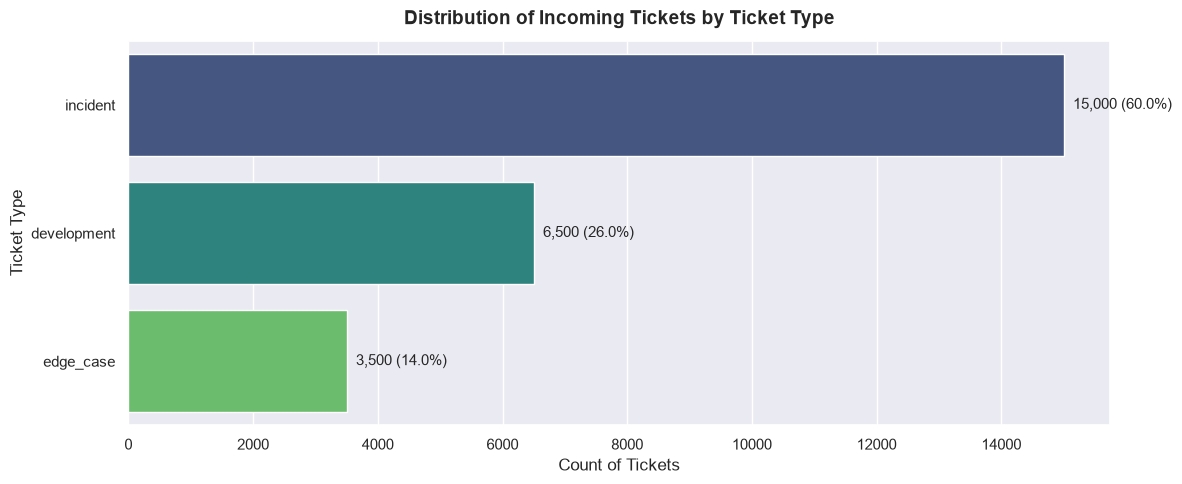

In [5]:
# Compute frequency and percentage breakdown for ticket_type
type_counts = df_in['ticket_type'].value_counts()
type_pcts = (type_counts / len(df_in)) * 100

# Create horizontal bar chart visualization
fig, ax = plt.subplots(figsize=(12, 5))
bars = sns.barplot(x=type_counts.values, y=type_counts.index, palette="viridis", ax=ax)

# Set chart titles and axis labels
ax.set_title("Distribution of Incoming Tickets by Ticket Type", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Count of Tickets", fontsize=12)
ax.set_ylabel("Ticket Type", fontsize=12)

# Annotate each bar with exact count and percentage
for i, (count, pct) in enumerate(zip(type_counts.values, type_pcts.values)):
    ax.text(count + max(type_counts.values)*0.01, i, f"{count:,} ({pct:.1f}%)", va="center", fontsize=11)

plt.tight_layout()
plt.show()

### Check 3 — Module Distribution (Incident Tickets Only)

**Why this check exists**: Verifies that incident tickets are balanced across SAP modules (FI, MM, SD, PP, BASIS, HR, ABAP).

C:\Users\user\AppData\Local\Temp\ipykernel_12508\3631370825.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=mod_counts.values, y=mod_counts.index, palette="mako", ax=ax)


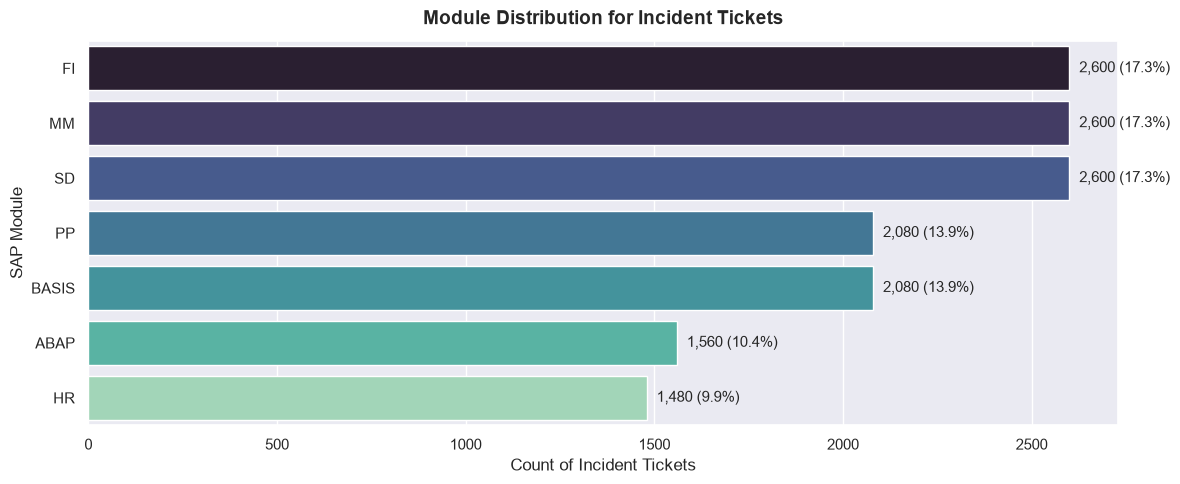

In [6]:
# Filter dataset strictly to incident tickets
df_incidents = df_in[df_in['ticket_type'] == 'incident']

# Compute module counts and percentages for incident rows
mod_counts = df_incidents['module'].value_counts()
mod_pcts = (mod_counts / len(df_incidents)) * 100

# Plot horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 5))
bars = sns.barplot(x=mod_counts.values, y=mod_counts.index, palette="mako", ax=ax)

# Set title and labels
ax.set_title("Module Distribution for Incident Tickets", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Count of Incident Tickets", fontsize=12)
ax.set_ylabel("SAP Module", fontsize=12)

# Annotate bars with count and percentage
for i, (count, pct) in enumerate(zip(mod_counts.values, mod_pcts.values)):
    ax.text(count + max(mod_counts.values)*0.01, i, f"{count:,} ({pct:.1f}%)", va="center", fontsize=11)

plt.tight_layout()
plt.show()

### Check 4 — Issue Type Distribution (Incident Tickets Only)

**Why this check exists**: Evaluates category balance across SAP issue types (Authorization, Configuration, Master Data, etc.).

C:\Users\user\AppData\Local\Temp\ipykernel_12508\1326616799.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(x=issue_counts.values, y=issue_counts.index, palette="rocket", ax=ax)


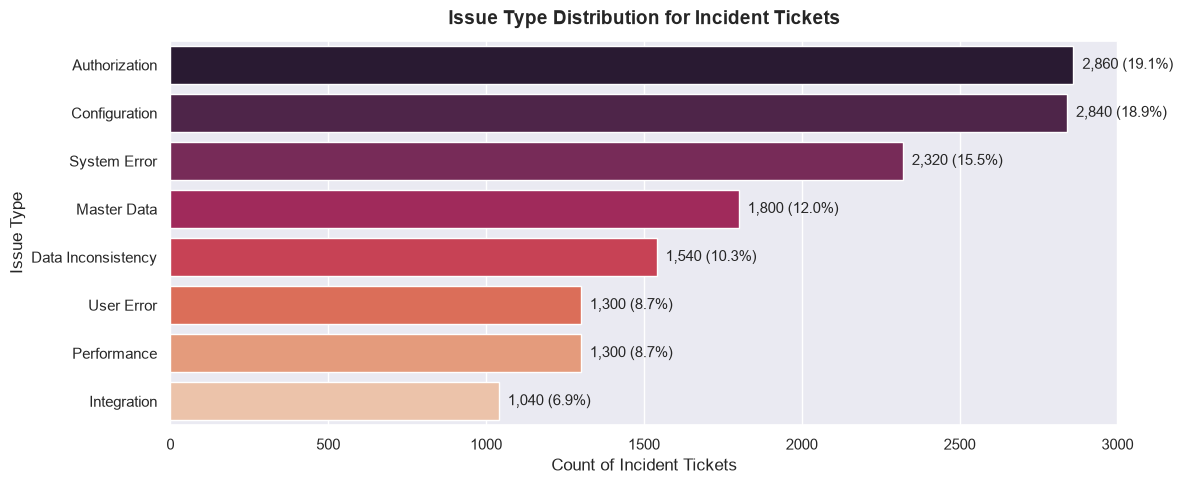

In [7]:
# Compute issue_type counts and percentages for incident tickets
issue_counts = df_incidents['issue_type'].value_counts()
issue_pcts = (issue_counts / len(df_incidents)) * 100

# Plot horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 5))
bars = sns.barplot(x=issue_counts.values, y=issue_counts.index, palette="rocket", ax=ax)

# Set title and labels
ax.set_title("Issue Type Distribution for Incident Tickets", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Count of Incident Tickets", fontsize=12)
ax.set_ylabel("Issue Type", fontsize=12)

# Annotate bars with count and percentage
for i, (count, pct) in enumerate(zip(issue_counts.values, issue_pcts.values)):
    ax.text(count + max(issue_counts.values)*0.01, i, f"{count:,} ({pct:.1f}%)", va="center", fontsize=11)

plt.tight_layout()
plt.show()

### Check 5 — Error Code Presence

**Why this check exists**: Confirms realistic mix between technical tickets (containing SAP error codes) and non-technical user descriptions.

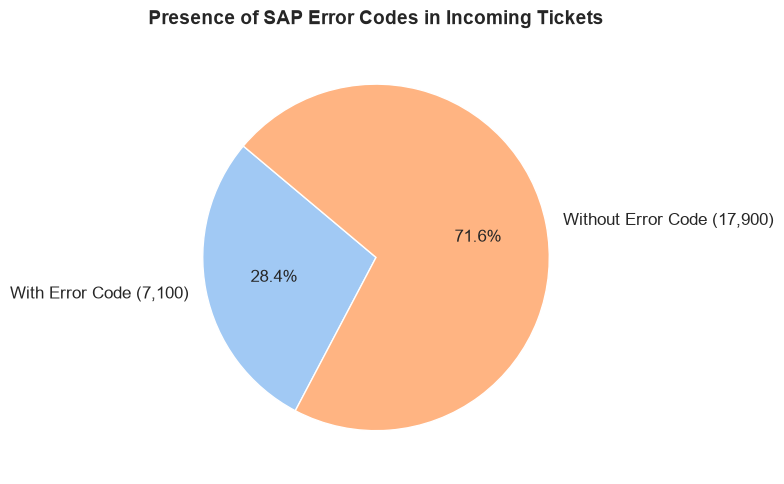

In [8]:
# Calculate count of tickets with vs without error codes
has_err_counts = df_in['has_error_code'].value_counts()

# Formulate chart labels with explicit counts
labels = [f"With Error Code ({has_err_counts.get(True, 0):,})", 
          f"Without Error Code ({has_err_counts.get(False, 0):,})"]

# Render pie chart displaying ratio
fig, ax = plt.subplots(figsize=(12, 5))
colors = sns.color_palette("pastel")[0:2]
ax.pie([has_err_counts.get(True, 0), has_err_counts.get(False, 0)], 
       labels=labels, autopct='%1.1f%%', startangle=140, colors=colors, textprops={'fontsize': 12})

ax.set_title("Presence of SAP Error Codes in Incoming Tickets", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

### Check 6 — Empty Text Fields

**Why this check exists**: Scans for null, empty string, or whitespace-only text values that would cause errors in BERT model tokenization.

In [9]:
# Detect rows where 'text' is null, empty string, or whitespace-only
empty_mask = df_in['text'].isna() | (df_in['text'].astype(str).str.strip() == "")
empty_count = empty_mask.sum()

# Print status report
if empty_count == 0:
    print(f"CHECK 6 OK: 0 empty or null text rows found.")
else:
    print(f"CHECK 6 PROBLEM: Found {empty_count:,} rows with empty or whitespace-only text!")

CHECK 6 OK: 0 empty or null text rows found.


### Check 7 — Duplicate Ticket Texts

**Why this check exists**: Identifies exact duplicate user texts across the dataset to prevent train-test data leakage.

In [10]:
# Detect duplicate text occurrences across entire incoming dataset
dup_mask = df_in.duplicated(subset=['text'], keep=False)
dup_count = df_in.duplicated(subset=['text'], keep='first').sum()

if dup_count == 0:
    print(f"CHECK 7 OK: 0 exact duplicate ticket texts found.")
else:
    print(f"CHECK 7 PROBLEM: Found {dup_count:,} duplicate ticket texts.")
    print("\n--- Sample Duplicate Texts (Top 3 Most Frequent) ---")
    dup_samples = df_in[dup_mask]['text'].value_counts().head(3)
    for idx, (txt, cnt) in enumerate(dup_samples.items(), 1):
        print(f"Sample {idx} (Occurrences: {cnt}): '{txt}'")

CHECK 7 PROBLEM: Found 748 duplicate ticket texts.

--- Sample Duplicate Texts (Top 3 Most Frequent) ---
Sample 1 (Occurrences: 18): 'please create a new user access report showing all roles and authorizations by department'
Sample 2 (Occurrences: 15): 'We need a new custom table to store additional vendor classification data'
Sample 3 (Occurrences: 15): 'We need a custom transaction to bulk update material prices from an excel upload'


### Check 8 — Word Count Distribution by Ticket Type

**Why this check exists**: Evaluates length variability per category (box plot + mean overlay) to confirm incidents display wider length variation than development requests.

C:\Users\user\AppData\Local\Temp\ipykernel_12508\1591669482.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_in, x='ticket_type', y='word_count', palette="Set2", ax=ax, boxprops=dict(alpha=0.7))


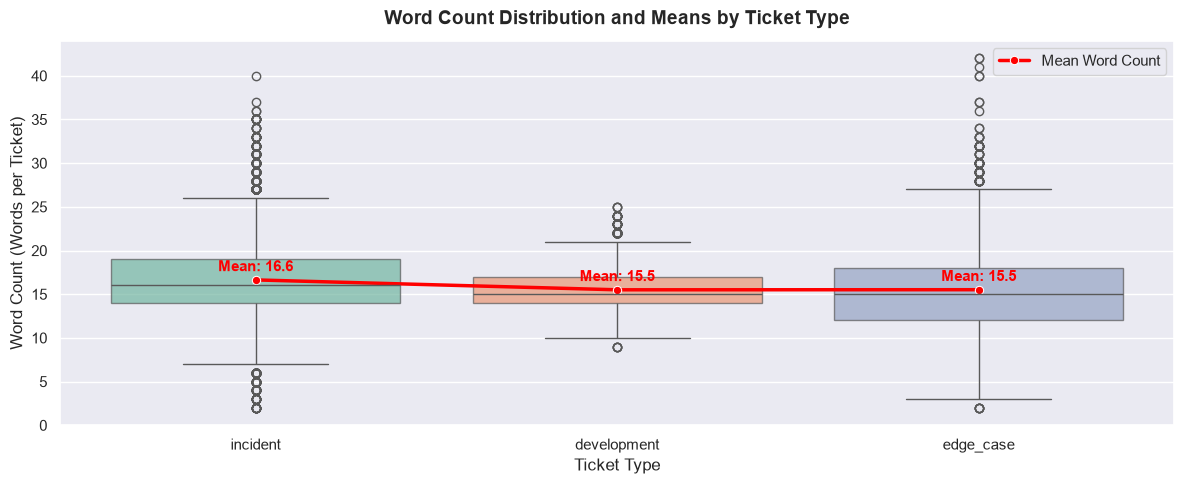

In [11]:
# Compute word count for each incoming ticket text
df_in['word_count'] = df_in['text'].astype(str).apply(lambda x: len(x.split()))

# Create composite boxplot with mean line overlay
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df_in, x='ticket_type', y='word_count', palette="Set2", ax=ax, boxprops=dict(alpha=0.7))

# Overlay mean word count line plot
means = df_in.groupby('ticket_type')['word_count'].mean().reset_index()
sns.lineplot(data=means, x='ticket_type', y='word_count', color='red', marker='o', linewidth=2.5, label='Mean Word Count', ax=ax)

# Annotate mean values above marker points
for _, row in means.iterrows():
    ax.text(row['ticket_type'], row['word_count'] + 1, f"Mean: {row['word_count']:.1f}", 
            ha='center', color='red', fontweight='bold', fontsize=11)

# Set chart titles and labels
ax.set_title("Word Count Distribution and Means by Ticket Type", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Ticket Type", fontsize=12)
ax.set_ylabel("Word Count (Words per Ticket)", fontsize=12)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### Check 9 — Sample Incoming Tickets (Visual Quality Inspection)

**Why this check exists**: Displays 3 random samples per `ticket_type` (9 total) to visually inspect text quality and non-technical phrasing.

In [12]:
# Print 3 random samples for each ticket_type to inspect phrasing quality
print("==================================================================")
print("SAMPLE TICKETS (Visual Inspection for Non-Technical Phrasing)")
print("==================================================================")

for t_type in ['incident', 'development', 'edge_case']:
    print(f"\n--- TICKET TYPE: {t_type.upper()} ---")
    samples = df_in[df_in['ticket_type'] == t_type].sample(n=3, random_state=42)
    for _, row in samples.iterrows():
        print(f"[{row['ticket_id']}] | Module: {row['module']} | Issue: {row['issue_type']} | Error: {row['error_code']}")
        print(f"Text: \"{row['text']}\"\n")

SAMPLE TICKETS (Visual Inspection for Non-Technical Phrasing)

--- TICKET TYPE: INCIDENT ---
[INC-011500] | Module: HR | Issue: Authorization | Error: nan
Text: "Why does my HR user keep getting authorization denied when trying to open employee salaries?"

[INC-006476] | Module: PP | Issue: Integration | Error: CO 624
Text: "I did the confirmation for the production order but the inventory is still the same and I see CO 624 in stock posting."

[INC-013168] | Module: SD | Issue: Authorization | Error: nan
Text: "Urgent! Sales team member is blocked from creating a delivery due to missing shipping point permission."


--- TICKET TYPE: DEVELOPMENT ---
[DEV-018107] | Module: ABAP | Issue: nan | Error: nan
Text: "We need to develop a custom database structure for storing new vendor classification metrics"

[DEV-021162] | Module: MM | Issue: nan | Error: nan
Text: "please create a custom PO dashboard that includes supplier evaluation metrics"

[DEV-016868] | Module: MM | Issue: nan | Error: 

### Check 10 — Total Resolved Count vs Incident + Edge Case Count

**Why this check exists**: Verifies that the number of records in `resolved_tickets.csv` exactly matches the count of `incident` + `edge_case` tickets in `incoming_tickets.csv` (development requests are excluded).

In [13]:
# Compute expected resolved count (incidents + edge cases only)
expected_resolved_count = len(df_in[df_in['ticket_type'].isin(['incident', 'edge_case'])])
actual_resolved_count = len(df_res)

print(f"Expected resolved count (incidents + edge cases): {expected_resolved_count:,}")
print(f"Actual resolved count (df_res):                  {actual_resolved_count:,}")

if expected_resolved_count == actual_resolved_count:
    print("CHECK 10 OK: Resolved count perfectly matches incident + edge case count.")
else:
    print(f"CHECK 10 PROBLEM: Discrepancy detected! Expected {expected_resolved_count:,}, got {actual_resolved_count:,}.")

Expected resolved count (incidents + edge cases): 18,500
Actual resolved count (df_res):                  18,500
CHECK 10 OK: Resolved count perfectly matches incident + edge case count.


### Check 11 — Empty Critical Fields in Resolved Records

**Why this check exists**: Audits `root_cause`, `fix`, and `tcodes_used` in resolved records to ensure no blank solutions enter the RAG vector DB.

In [14]:
# Check for null or empty values across critical resolution fields
critical_fields = ['root_cause', 'fix', 'tcodes_used']

for field in critical_fields:
    empty_cnt = (df_res[field].isna() | (df_res[field].astype(str).str.strip() == "")).sum()
    if empty_cnt == 0:
        print(f"Field '{field}': OK (0 empty values)")
    else:
        print(f"Field '{field}': PROBLEM ({empty_cnt:,} empty values found)")

Field 'root_cause': OK (0 empty values)
Field 'fix': OK (0 empty values)
Field 'tcodes_used': OK (0 empty values)


### Check 12 — Resolution Time by Module

**Why this check exists**: Plots mean resolution time in minutes per SAP module with standard deviation error bars to inspect numerical sanity.

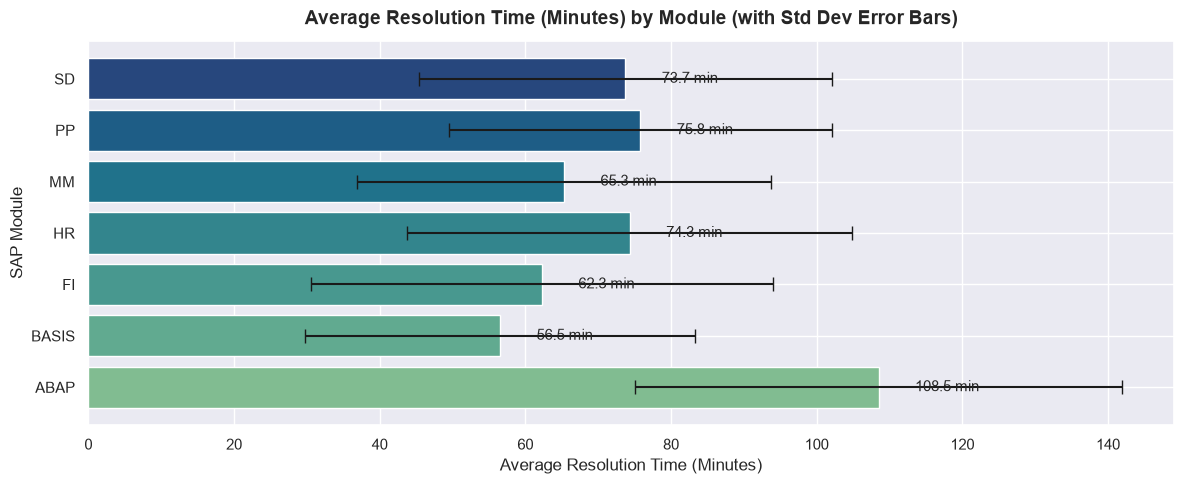

In [15]:
# Group resolution_time_minutes by module (mean and std)
res_stats = df_res.groupby('module')['resolution_time_minutes'].agg(['mean', 'std']).reset_index()

# Create horizontal bar chart with error bars
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(res_stats['module'], res_stats['mean'], xerr=res_stats['std'], capsize=5, color=sns.color_palette("crest", len(res_stats)))

# Set chart title and axis labels
ax.set_title("Average Resolution Time (Minutes) by Module (with Std Dev Error Bars)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Average Resolution Time (Minutes)", fontsize=12)
ax.set_ylabel("SAP Module", fontsize=12)

# Annotate bars with mean values
for bar, mean_val in zip(bars, res_stats['mean']):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, f"{mean_val:.1f} min", va='center', fontsize=11)

plt.tight_layout()
plt.show()

### Check 13 — Escalation Rate by Module

**Why this check exists**: Calculates and plots the percentage of escalated tickets (`escalated == 'Yes'`) per module.

C:\Users\user\AppData\Local\Temp\ipykernel_12508\2474020376.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(data=esc_counts, x='escalation_rate', y='module', palette="flare", ax=ax)


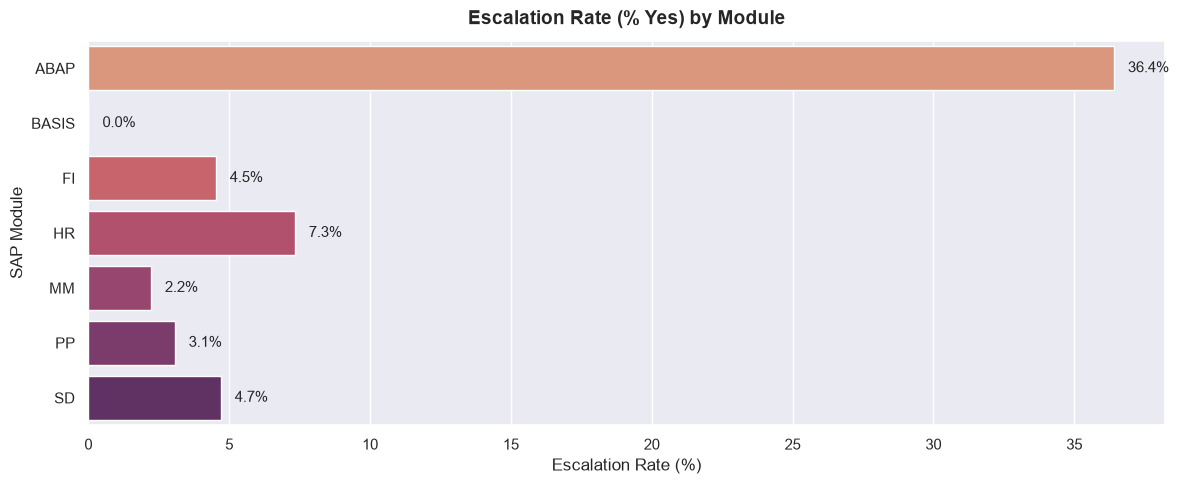

In [16]:
# Calculate escalation percentage per module
esc_counts = df_res.groupby('module')['escalated'].apply(lambda x: (x == 'Yes').mean() * 100).reset_index()
esc_counts.columns = ['module', 'escalation_rate']

# Plot horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 5))
bars = sns.barplot(data=esc_counts, x='escalation_rate', y='module', palette="flare", ax=ax)

# Set title and labels
ax.set_title("Escalation Rate (% Yes) by Module", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Escalation Rate (%)", fontsize=12)
ax.set_ylabel("SAP Module", fontsize=12)

# Annotate bars with exact percentages
for i, rate in enumerate(esc_counts['escalation_rate']):
    ax.text(rate + 0.5, i, f"{rate:.1f}%", va="center", fontsize=11)

plt.tight_layout()
plt.show()

### Check 14 — Sample Resolved Records

**Why this check exists**: Prints 3 random resolved records formatted clearly to inspect resolution structure.

In [17]:
# Print 3 random resolved records formatted clearly
print("==================================================================")
print("SAMPLE RESOLVED RECORDS (Structured RAG Knowledge Base Checks)")
print("==================================================================")

res_samples = df_res.sample(n=3, random_state=42)
for idx, row in res_samples.iterrows():
    print(f"[{row['ticket_id']}] Type: {row['ticket_type']} | Module: {row['module']} | Issue: {row['issue_type']}")
    print(f"  Problem:    {row['problem']}")
    print(f"  Error Code: {row['error_code']}")
    print(f"  Root Cause: {row['root_cause']}")
    print(f"  Fix:        {row['fix']}")
    print(f"  TCodes:     {row['tcodes_used']} | Time: {row['resolution_time_minutes']} min | Escalated: {row['escalated']}\n")

SAMPLE RESOLVED RECORDS (Structured RAG Knowledge Base Checks)
[INC-003435] Type: incident | Module: HR | Issue: Master Data
  Problem:    I added someone last month and now they arent showing in payroll. what did i do wrong??
  Error Code: nan
  Root Cause: Employee master data incomplete or incorrect — missing infotype record, wrong organizational assignment, or incomplete payroll-relevant data causing processing failure.
  Fix:        1. Open employee master data in PA20 and review all relevant infotypes
2. Check IT0001 (organizational assignment) for correct personnel area and cost center
3. Check IT0008 (basic pay) if payroll issue — verify wage types and amounts
4. Check IT0007 (planned working time) if time evaluation issue
5. Correct missing or incorrect infotype records using PA30
6. Run payroll simulation in PY60 to verify fix before actual payroll run
  TCodes:     PA20, PA30, IT0001, IT0008, PY60 | Time: 42 min | Escalated: No

[INC-008629] Type: incident | Module: SD | Iss

# SECTION 2 — DATA CLEANING

Automated data cleaning, deduplication, resolution syncing, shuffling, and clean file persistence.

## Execute Data Cleaning Pipeline

**Why this cell exists**: Executes the data cleaning pipeline:
1. Remove null/empty text rows
2. Remove exact duplicate texts
2b. Sync resolved tickets after duplicate removal (remove orphaned resolved records)
3. Remove malformed resolved records
4. Shuffle datasets reproducibly (`random_state=42`), preserving `ticket_id` values
5. Save cleaned files to `incoming_tickets_clean.csv` and `resolved_tickets_clean.csv`.

In [18]:
print(f"Pre-cleaning incoming ticket count: {len(df_in):,}")
print(f"Pre-cleaning resolved ticket count: {len(df_res):,}\n")

# Cleaning Step 1 — Remove empty text rows
initial_in_len = len(df_in)
df_in_clean = df_in[df_in['text'].notna() & (df_in['text'].astype(str).str.strip() != "")].copy()
removed_empty_text = initial_in_len - len(df_in_clean)
print(f"Cleaning Step 1: Removed {removed_empty_text:,} rows with empty text fields")

# Cleaning Step 2 — Remove duplicate texts (keep first occurrence)
len_before_dup = len(df_in_clean)
df_in_clean = df_in_clean.drop_duplicates(subset=['text'], keep='first').copy()
removed_duplicates = len_before_dup - len(df_in_clean)
print(f"Cleaning Step 2: Removed {removed_duplicates:,} duplicate rows")

# Cleaning Step 2b — Sync resolved tickets after duplicate removal
surviving_ids = set(df_in_clean["ticket_id"].values)
before_sync = len(df_res)
df_res_clean = df_res[df_res["ticket_id"].isin(surviving_ids)].reset_index(drop=True)
removed_orphans = before_sync - len(df_res_clean)
print(f"Cleaning Step 2b: Removed {removed_orphans:,} orphaned resolved records whose incoming ticket was removed as a duplicate.")

# Cleaning Step 3 — Remove malformed resolved records
initial_res_len = len(df_res_clean)
df_res_clean = df_res_clean[
    df_res_clean['root_cause'].notna() & (df_res_clean['root_cause'].astype(str).str.strip() != "") &
    df_res_clean['fix'].notna() & (df_res_clean['fix'].astype(str).str.strip() != "")
].copy()
removed_res_malformed = initial_res_len - len(df_res_clean)
print(f"Cleaning Step 3: Removed {removed_res_malformed:,} malformed resolved records")

# Cleaning Step 4 — Shuffle both dataframes reproducibly (preserving ticket_id column)
df_in_clean = df_in_clean.sample(frac=1, random_state=42).reset_index(drop=True)
df_res_clean = df_res_clean.sample(frac=1, random_state=42).reset_index(drop=True)
print("Cleaning Step 4: Data shuffled with random_state=42. ticket_id values preserved, row ordering randomized.")

# Cleaning Step 5 — Save clean CSV files
CLEAN_INCOMING_PATH = "C:/ARIA/ARIA/data/synthetic/incoming_tickets_clean.csv"
CLEAN_RESOLVED_PATH = "C:/ARIA/ARIA/data/synthetic/resolved_tickets_clean.csv"

# Drop temporary helper column 'word_count' if present before exporting
if 'word_count' in df_in_clean.columns:
    df_in_clean = df_in_clean.drop(columns=['word_count'])

df_in_clean.to_csv(CLEAN_INCOMING_PATH, index=False)
df_res_clean.to_csv(CLEAN_RESOLVED_PATH, index=False)

print(f"\nCleaning Step 5: Clean files saved.")
print(f"  Final Clean Incoming Tickets ({CLEAN_INCOMING_PATH}): {len(df_in_clean):,} rows")
print(f"  Final Clean Resolved Records ({CLEAN_RESOLVED_PATH}): {len(df_res_clean):,} rows")
print("All downstream training notebooks must use the _clean versions.")

Pre-cleaning incoming ticket count: 25,000
Pre-cleaning resolved ticket count: 18,500

Cleaning Step 1: Removed 0 rows with empty text fields
Cleaning Step 2: Removed 748 duplicate rows
Cleaning Step 2b: Removed 398 orphaned resolved records whose incoming ticket was removed as a duplicate.
Cleaning Step 3: Removed 0 malformed resolved records
Cleaning Step 4: Data shuffled with random_state=42. ticket_id values preserved, row ordering randomized.

Cleaning Step 5: Clean files saved.
  Final Clean Incoming Tickets (C:/ARIA/ARIA/data/synthetic/incoming_tickets_clean.csv): 24,252 rows
  Final Clean Resolved Records (C:/ARIA/ARIA/data/synthetic/resolved_tickets_clean.csv): 18,102 rows
All downstream training notebooks must use the _clean versions.


# SECTION 3 — FINAL VERIFICATION

Automated verification checks reloaded from disk to guarantee data cleanliness before model training.

## Final Health Verification Checks

**Why this cell exists**: Reloads `incoming_tickets_clean.csv` and `resolved_tickets_clean.csv` from disk and runs automated pass/fail verification checks (Checks A through F, including E1 & E2).

In [19]:
# Reload cleaned datasets from disk to verify saved integrity
df_in_v = pd.read_csv("C:/ARIA/ARIA/data/synthetic/incoming_tickets_clean.csv")
df_res_v = pd.read_csv("C:/ARIA/ARIA/data/synthetic/resolved_tickets_clean.csv")

failed_checks = 0

# Check A — Total incoming count [24,000, 25,000]
total_in_cnt = len(df_in_v)
if 24000 <= total_in_cnt <= 25000:
    print(f"[PASS] Check A — Total incoming count is {total_in_cnt:,} (acceptable range 24,000–25,000)")
else:
    print(f"[FAIL] Check A — Total incoming count is {total_in_cnt:,} (outside 24,000–25,000)")
    failed_checks += 1

# Check B — No empty text fields
empty_cnt = (df_in_v['text'].isna() | (df_in_v['text'].astype(str).str.strip() == "")).sum()
if empty_cnt == 0:
    print("[PASS] Check B — No empty text fields remaining")
else:
    print(f"[FAIL] Check B — Found {empty_cnt:,} empty text fields")
    failed_checks += 1

# Check C — No duplicate texts
dup_cnt = df_in_v.duplicated(subset=['text']).sum()
if dup_cnt == 0:
    print("[PASS] Check C — 0 exact duplicate texts remaining")
else:
    print(f"[FAIL] Check C — Found {dup_cnt:,} duplicate texts")
    failed_checks += 1

# Check D — Module distribution balanced (no single module > 3,000 incident tickets)
incidents_v = df_in_v[df_in_v['ticket_type'] == 'incident']
max_mod_cnt = incidents_v['module'].value_counts().max()
if max_mod_cnt <= 3000:
    print(f"[PASS] Check D — Module distribution balanced (highest module count: {max_mod_cnt:,} <= 3,000)")
else:
    print(f"[FAIL] Check D — Module distribution unbalanced (highest module count: {max_mod_cnt:,} > 3,000)")
    failed_checks += 1

# Check E1 — Resolved records complete (no empty root_cause or fix)
incomplete_res = (
    df_res_v['root_cause'].isna() | (df_res_v['root_cause'].astype(str).str.strip() == "") |
    df_res_v['fix'].isna() | (df_res_v['fix'].astype(str).str.strip() == "")
).sum()
if incomplete_res == 0:
    print("[PASS] Check E1 — 0 incomplete resolved records remaining")
else:
    print(f"[FAIL] Check E1 — Found {incomplete_res:,} incomplete resolved records")
    failed_checks += 1

# Check E2 — Resolved and incoming files are in 100% sync
inc_inc_edge_ids = set(df_in_v[df_in_v['ticket_type'].isin(['incident', 'edge_case'])]['ticket_id'].values)
res_ids = set(df_res_v['ticket_id'].values)

missing_in_resolved = inc_inc_edge_ids - res_ids
missing_in_incoming = res_ids - inc_inc_edge_ids

if len(missing_in_resolved) == 0 and len(missing_in_incoming) == 0:
    print("[PASS] Check E2 — Resolved and incoming files are in 100% sync (zero ID mismatches in both directions)")
else:
    print("[FAIL] Check E2 — Mismatch detected between incoming (incident/edge) and resolved files:")
    if len(missing_in_resolved) > 0:
        print(f"  {len(missing_in_resolved):,} incoming incident/edge tickets have no resolved record")
    if len(missing_in_incoming) > 0:
        print(f"  {len(missing_in_incoming):,} resolved records have no matching incoming ticket")
    failed_checks += 1

# Check F — Shuffle verified (first 10 rows contain multiple ticket types)
first_10_types = df_in_v['ticket_type'].head(10).unique()
if len(first_10_types) > 1:
    print(f"[PASS] Check F — Shuffle verified. First 10 rows contain mixed ticket types: {list(first_10_types)}")
else:
    print(f"[FAIL] Check F — Shuffle failed! First 10 rows are all of type: {first_10_types[0]}")
    failed_checks += 1

# Print overall summary notice
print("\n" + "=" * 55)
if failed_checks == 0:
    print("ALL CHECKS PASSED. Data is clean and ready for model training.")
else:
    print(f"WARNING: {failed_checks} checks failed. Review failed checks before proceeding to model training.")
print("=" * 55)

[PASS] Check A — Total incoming count is 24,252 (acceptable range 24,000–25,000)
[PASS] Check B — No empty text fields remaining
[PASS] Check C — 0 exact duplicate texts remaining
[PASS] Check D — Module distribution balanced (highest module count: 2,551 <= 3,000)
[PASS] Check E1 — 0 incomplete resolved records remaining
[PASS] Check E2 — Resolved and incoming files are in 100% sync (zero ID mismatches in both directions)
[PASS] Check F — Shuffle verified. First 10 rows contain mixed ticket types: ['development', 'incident', 'edge_case']

ALL CHECKS PASSED. Data is clean and ready for model training.
